# Tugas IPSD: Klasifikasi Citra Penyakit Daun (PlantVillage)
**Kelompok:** Ghufron, Bintang, Yeni

**Metode:** 5-Fold Cross Validation dengan Simple CNN, Modified CNN, dan InceptionV3

**Optimasi:** Mixed Precision Training 

## 1. Modul Preprocessing & Arsitektur Model
Script ini membuat preprocessing.py untuk menyiapkan DataFrame dan models_hub.py untuk membangun 3 arsitektur model.

In [1]:
%%writefile preprocessing.py
import os
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def load_data_paths(base_dir):
    filepaths, labels = [], []
    for folder in os.listdir(base_dir):
        folder_path = os.path.join(base_dir, folder)
        if os.path.isdir(folder_path):
            for file in os.listdir(folder_path):
                filepaths.append(os.path.join(folder_path, file))
                labels.append(folder)
    return pd.DataFrame({'filepath': filepaths, 'label': labels})

def get_data_generators():
    train_datagen = ImageDataGenerator(
        rescale=1./255, rotation_range=20, width_shift_range=0.2,
        height_shift_range=0.2, horizontal_flip=True
    )
    val_datagen = ImageDataGenerator(rescale=1./255)
    return train_datagen, val_datagen

Overwriting preprocessing.py


In [11]:
%%writefile models_hub.py
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3
import tensorflow.keras.backend as K

def f1_score(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())
    return 2 * (precision * recall) / (precision + recall + K.epsilon())

def compile_and_return(model):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy',
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall'),
                           tf.keras.metrics.AUC(name='auc'),
                           f1_score])
    return model

# ALGORITMA 1: Simple CNN
def build_algo1_simple_cnn(input_shape=(128, 128, 3), num_classes=38):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax', dtype='float32')
    ])
    return compile_and_return(model)

# ALGORITMA 2: Modified CNN
def build_algo2_modified_cnn(input_shape=(128, 128, 3), num_classes=38):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax', dtype='float32') 
    ])
    return compile_and_return(model)

# ALGORITMA 3: Transfer Learning (InceptionV3)
def build_algo3_inceptionv3(input_shape=(128, 128, 3), num_classes=38):
    base = InceptionV3(input_shape=input_shape, include_top=False, weights='imagenet')
    base.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)

    model = models.Model(inputs, outputs)
    return compile_and_return(model)

Overwriting models_hub.py


## 2. Inisialisasi Environment & Optimasi Mixed Precision
Membaca letak folder gambar serta mengaktifkan akselerasi GPU agar training lebih cepat tanpa mengorbankan akurasi.

In [ ]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append('.')
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.callbacks import CSVLogger, ReduceLROnPlateau, EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import mixed_precision

mixed_precision.set_global_policy('mixed_float16')

from preprocessing import load_data_paths, get_data_generators
from models_hub import import build_algo1_simple_cnn, build_algo2_modified_cnn, build_algo3_inceptionv3

BASE_DIR = "dataset_daun/plantvillage dataset/color"
df = load_data_paths(BASE_DIR)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_dg, val_dg = get_data_generators()
common_args = dict(x_col='filepath', y_col='label', target_size=(128, 128), batch_size=16, class_mode='categorical')

## 3. Algoritma 1: Simple CNN

In [4]:
PILIHAN_ALGO = 1
tf.keras.backend.clear_session()
fold_no = 1
cv_results = []
print(f"=== MEMULAI 5-FOLD CROSS VALIDATION UNTUK ALGORITMA {PILIHAN_ALGO} ===")

for train_index, val_index in skf.split(df['filepath'], df['label']):
    print(f"\n--- Melatih Fold Ke-{fold_no} ---")
    train_df = df.iloc[train_index]
    val_df = df.iloc[val_index]

    train_gen = train_dg.flow_from_dataframe(train_df, shuffle=True, **common_args)
    val_gen = val_dg.flow_from_dataframe(val_df, shuffle=False, **common_args)

    model = build_algo1_simple_cnn()

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    ]

    model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks, verbose=1)

    print(f"Mengevaluasi Fold {fold_no}...")
    scores = model.evaluate(val_gen, verbose=0)
    cv_results.append(scores)

    if fold_no == 5:
        model.save(f'model_algo{PILIHAN_ALGO}_final_fold.keras')
        val_gen_final = val_gen
    
    fold_no += 1
print("\n=== PELATIHAN 5-FOLD SELESAI ===")


=== MEMULAI 5-FOLD CROSS VALIDATION UNTUK ALGORITMA 1 ===

--- Melatih Fold Ke-1 ---
Found 43444 validated image filenames belonging to 38 classes.
Found 10861 validated image filenames belonging to 38 classes.
Epoch 1/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 222s 82ms/step - accuracy: 0.4987 - auc: 0.9321 - f1_score: 0.4384 - loss: 1.8237 - precision: 0.8254 - recall: 0.3238 - val_accuracy: 0.5262 - val_auc: 0.9305 - val_f1_score: 0.5039 - val_loss: 1.8014 - val_precision: 0.6702 - val_recall: 0.4583 - learning_rate: 3.0000e-04
Epoch 2/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 202s 74ms/step - accuracy: 0.6836 - auc: 0.9774 - f1_score: 0.6632 - loss: 1.0615 - precision: 0.8396 - recall: 0.5560 - val_accuracy: 0.6629 - val_auc: 0.9687 - val_f1_score: 0.6349 - val_loss: 1.1502 - val_precision: 0.7741 - val_recall: 0.5820 - learning_rate: 3.0000e-04
Epoch 3/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 205s 75ms/step - accuracy: 0.7413 - auc: 0.9845 - f1_score: 0.7296 - loss: 0.8525 - precision: 0.8564 - recall: 

=== HASIL RATA-RATA 5-FOLD CROSS VALIDATION (ALGO 1) ===
Loss             : 0.5635
Accuracy         : 0.8354
Precision        : 0.8664
Recall           : 0.8112
ROC-AUC          : 0.9875
F1-Score         : 0.8329

Menghasilkan Confusion Matrix dari Fold 5...
679/679 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step


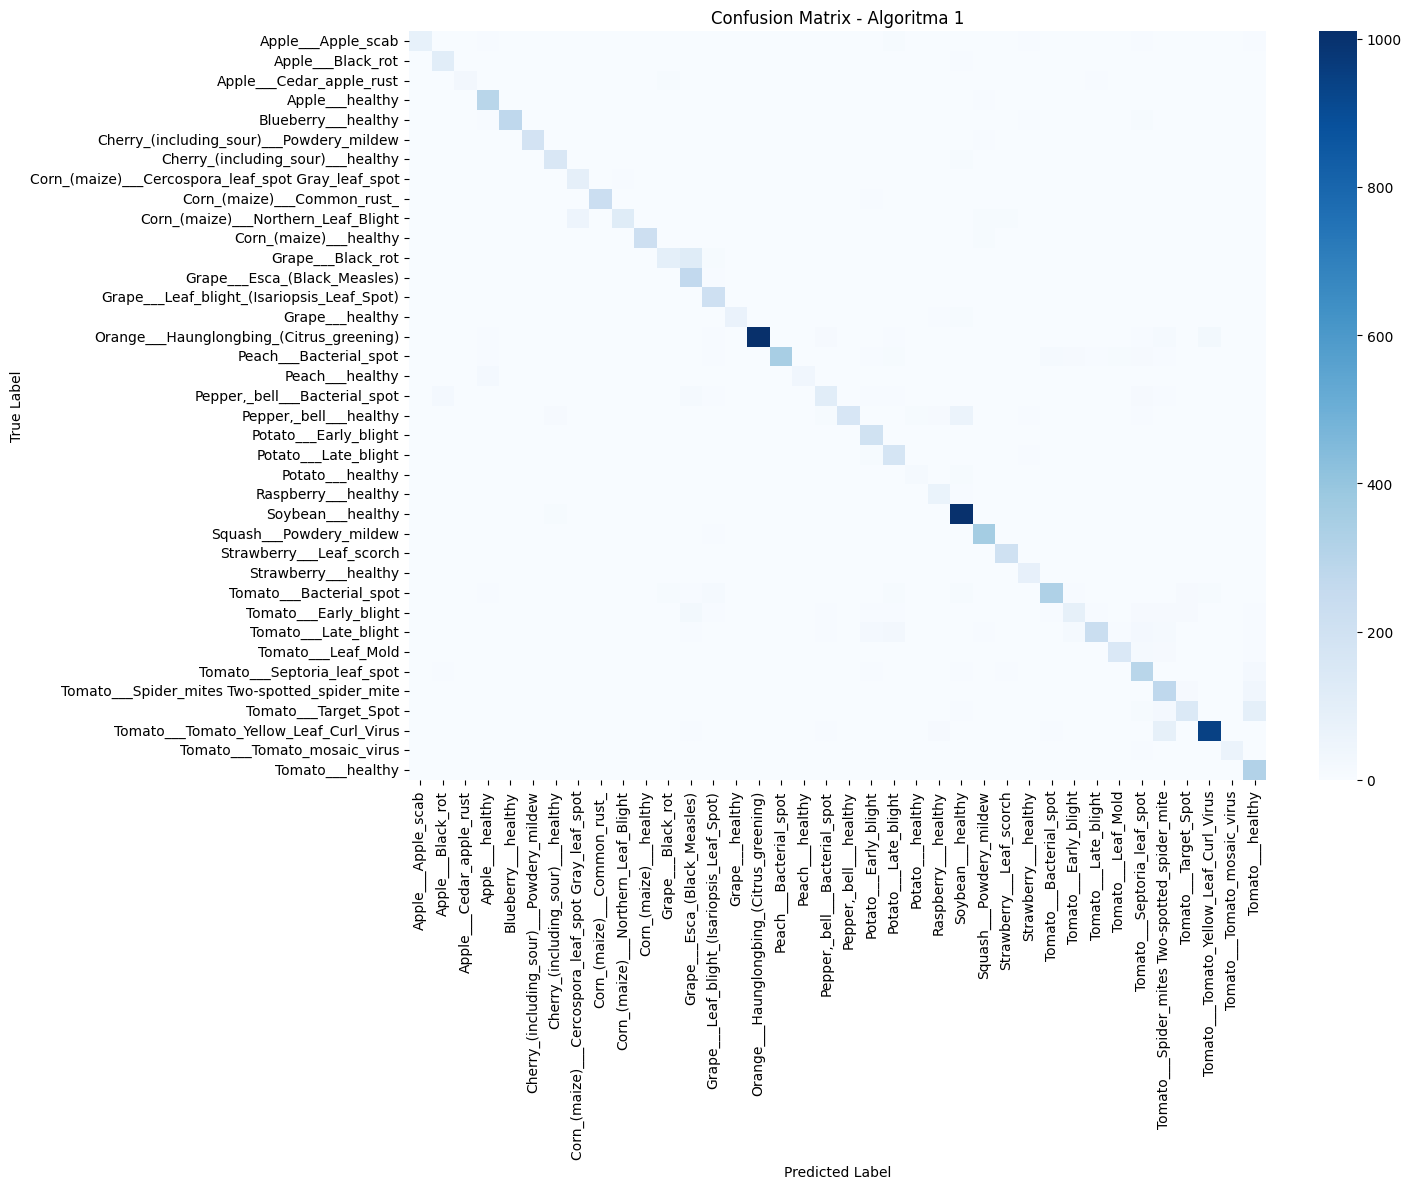

In [5]:
cv_results = np.array(cv_results)
avg_scores = np.mean(cv_results, axis=0)

print(f"=== HASIL RATA-RATA 5-FOLD CROSS VALIDATION (ALGO {PILIHAN_ALGO}) ===")
print(f"Loss             : {avg_scores[0]:.4f}")
print(f"Accuracy         : {avg_scores[1]:.4f}")
print(f"Precision        : {avg_scores[2]:.4f}")
print(f"Recall           : {avg_scores[3]:.4f}")
print(f"ROC-AUC          : {avg_scores[4]:.4f}")
print(f"F1-Score         : {avg_scores[5]:.4f}")
print("===============================================")

print("\nMenghasilkan Confusion Matrix dari Fold 5...")
val_gen_final.reset()
y_true = val_gen_final.classes
y_pred_prob = model.predict(val_gen_final, steps=len(val_gen_final), verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
class_names = list(val_gen_final.class_indices.keys())
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Algoritma {PILIHAN_ALGO}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(f'confusion_matrix_algo{PILIHAN_ALGO}.png', dpi=200)
plt.show()

## 4. Algoritma 2: Modified CNN

In [6]:
PILIHAN_ALGO = 2
tf.keras.backend.clear_session()
fold_no = 1
cv_results = []
print(f"=== MEMULAI 5-FOLD CROSS VALIDATION UNTUK ALGORITMA {PILIHAN_ALGO} ===")

for train_index, val_index in skf.split(df['filepath'], df['label']):
    print(f"\n--- Melatih Fold Ke-{fold_no} ---")
    train_df = df.iloc[train_index]
    val_df = df.iloc[val_index]

    train_gen = train_dg.flow_from_dataframe(train_df, shuffle=True, **common_args)
    val_gen = val_dg.flow_from_dataframe(val_df, shuffle=False, **common_args)

    model = build_algo2_modified_cnn()

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    ]

    model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks, verbose=1)

    print(f"Mengevaluasi Fold {fold_no}...")
    scores = model.evaluate(val_gen, verbose=0)
    cv_results.append(scores)

    if fold_no == 5:
        model.save(f'model_algo{PILIHAN_ALGO}_final_fold.keras')
        val_gen_final = val_gen
    
    fold_no += 1
print("\n=== PELATIHAN 5-FOLD SELESAI ===")

=== MEMULAI 5-FOLD CROSS VALIDATION UNTUK ALGORITMA 2 ===

--- Melatih Fold Ke-1 ---
Found 43444 validated image filenames belonging to 38 classes.
Found 10861 validated image filenames belonging to 38 classes.
Epoch 1/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 425s 156ms/step - accuracy: 0.4841 - auc: 0.9335 - f1_score: 0.3931 - loss: 1.8711 - precision: 0.8258 - recall: 0.2752 - val_accuracy: 0.6221 - val_auc: 0.9739 - val_f1_score: 0.5309 - val_loss: 1.2260 - val_precision: 0.8344 - val_recall: 0.4811 - learning_rate: 3.0000e-04
Epoch 2/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 644s 237ms/step - accuracy: 0.6501 - auc: 0.9750 - f1_score: 0.6089 - loss: 1.1893 - precision: 0.8509 - recall: 0.4826 - val_accuracy: 0.6228 - val_auc: 0.9616 - val_f1_score: 0.5834 - val_loss: 1.3147 - val_precision: 0.7116 - val_recall: 0.5455 - learning_rate: 3.0000e-04
Epoch 3/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 644s 237ms/step - accuracy: 0.7156 - auc: 0.9836 - f1_score: 0.6891 - loss: 0.9444 - precision: 0.8617 - recall

=== HASIL RATA-RATA 5-FOLD CROSS VALIDATION (ALGO 2) ===
Loss             : 0.5896
Accuracy         : 0.8199
Precision        : 0.8722
Recall           : 0.7776
ROC-AUC          : 0.9893
F1-Score         : 0.8067

Menghasilkan Confusion Matrix dari Fold 5...
679/679 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step


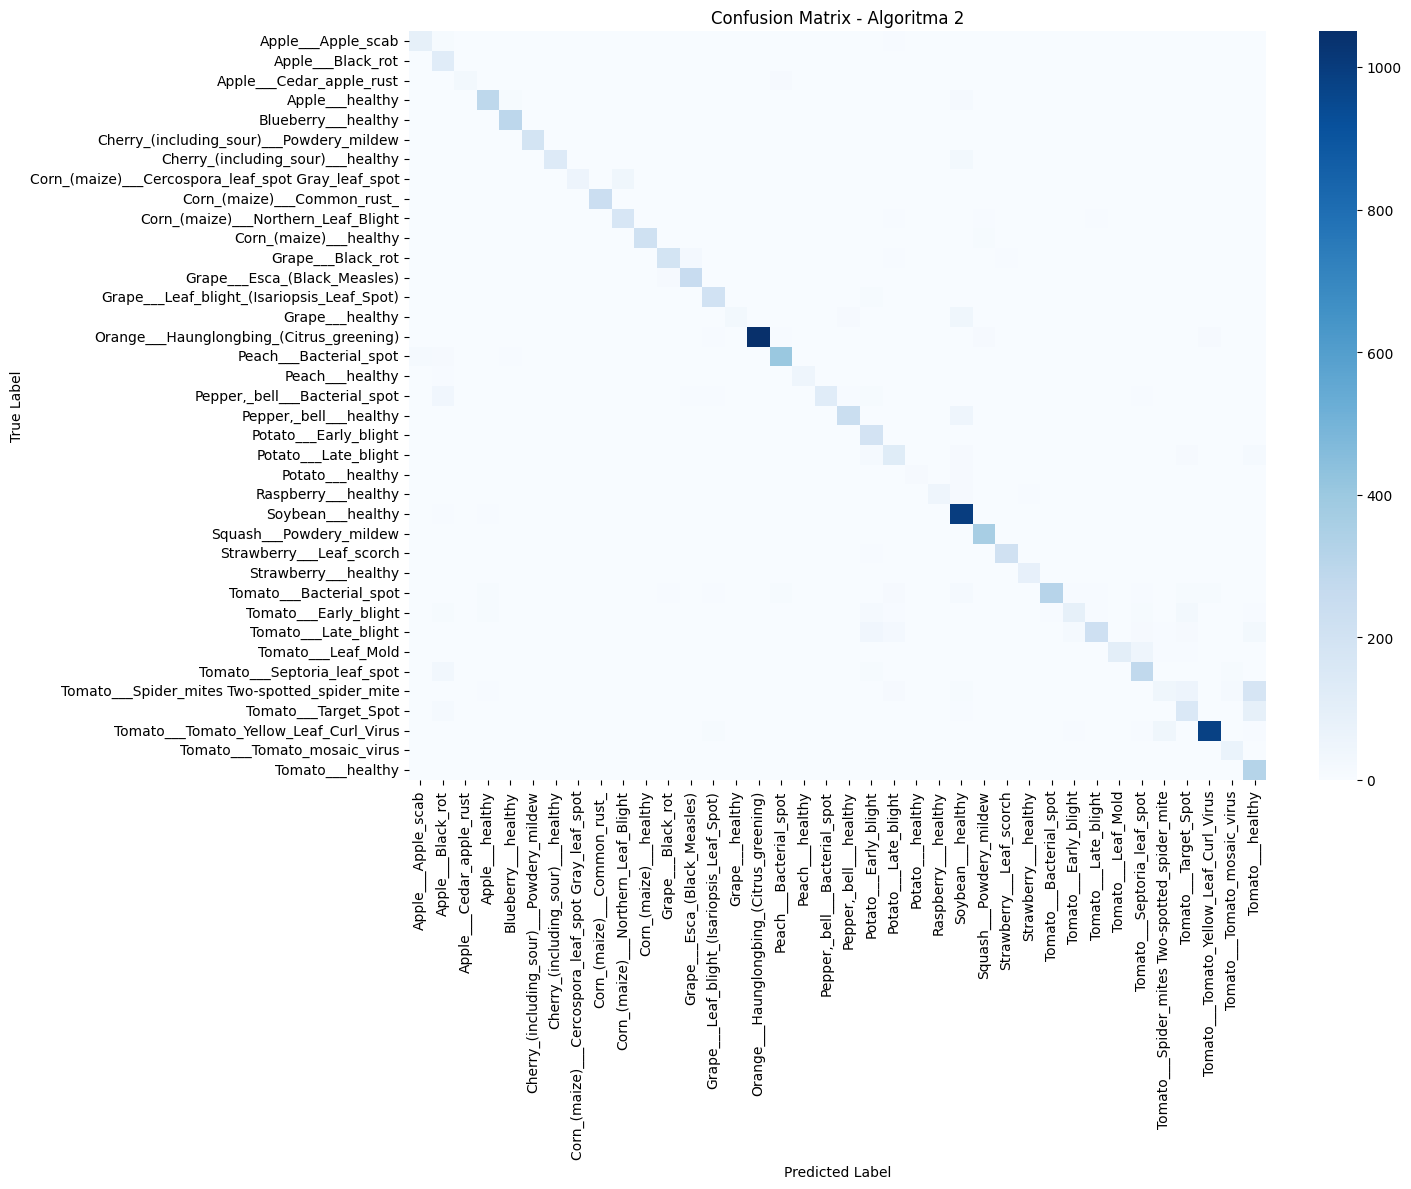

In [7]:
cv_results = np.array(cv_results)
avg_scores = np.mean(cv_results, axis=0)

print(f"=== HASIL RATA-RATA 5-FOLD CROSS VALIDATION (ALGO {PILIHAN_ALGO}) ===")
print(f"Loss             : {avg_scores[0]:.4f}")
print(f"Accuracy         : {avg_scores[1]:.4f}")
print(f"Precision        : {avg_scores[2]:.4f}")
print(f"Recall           : {avg_scores[3]:.4f}")
print(f"ROC-AUC          : {avg_scores[4]:.4f}")
print(f"F1-Score         : {avg_scores[5]:.4f}")
print("===============================================")

print("\nMenghasilkan Confusion Matrix dari Fold 5...")
val_gen_final.reset()
y_true = val_gen_final.classes
y_pred_prob = model.predict(val_gen_final, steps=len(val_gen_final), verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
class_names = list(val_gen_final.class_indices.keys())
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Algoritma {PILIHAN_ALGO}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(f'confusion_matrix_algo{PILIHAN_ALGO}.png', dpi=200)
plt.show()

## 5. Algoritma 3: InceptionV3 (Transfer Learning)

In [ ]:
PILIHAN_ALGO = 3
tf.keras.backend.clear_session()
fold_no = 1
cv_results = []
print(f"=== MEMULAI 5-FOLD CROSS VALIDATION UNTUK ALGORITMA {PILIHAN_ALGO} ===")


for train_index, val_index in skf.split(df['filepath'], df['label']):
    print(f"\n--- Melatih Fold Ke-{fold_no} ---")
    train_df = df.iloc[train_index]
    val_df = df.iloc[val_index]

    train_gen = train_dg.flow_from_dataframe(train_df, shuffle=True, **common_args)
    val_gen = val_dg.flow_from_dataframe(val_df, shuffle=False, **common_args)

    model = build_algo3_inceptionv3()

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    ]

    model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks, verbose=1)

    print(f"Mengevaluasi Fold {fold_no}...")
    scores = model.evaluate(val_gen, verbose=0)
    cv_results.append(scores)

    if fold_no == 5:
        model.save(f'model_algo{PILIHAN_ALGO}_final_fold.keras')
        val_gen_final = val_gen
    
    fold_no += 1
print("\n=== PELATIHAN 5-FOLD SELESAI ===")

=== MEMULAI 5-FOLD CROSS VALIDATION UNTUK ALGORITMA 3 ===

--- Melatih Fold Ke-1 ---
Found 43444 validated image filenames belonging to 38 classes.
Found 10861 validated image filenames belonging to 38 classes.
Epoch 1/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 291s 106ms/step - accuracy: 0.6502 - auc: 0.9627 - f1_score: 0.6386 - loss: 1.2514 - precision: 0.8000 - recall: 0.5527 - val_accuracy: 0.7639 - val_auc: 0.9817 - val_f1_score: 0.7453 - val_loss: 0.8128 - val_precision: 0.8431 - val_recall: 0.6926 - learning_rate: 3.0000e-04
Epoch 2/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 278s 102ms/step - accuracy: 0.7643 - auc: 0.9825 - f1_score: 0.7640 - loss: 0.7941 - precision: 0.8393 - recall: 0.7052 - val_accuracy: 0.8019 - val_auc: 0.9876 - val_f1_score: 0.7922 - val_loss: 0.6507 - val_precision: 0.8639 - val_recall: 0.7497 - learning_rate: 3.0000e-04
Epoch 3/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 277s 102ms/step - accuracy: 0.7837 - auc: 0.9840 - f1_score: 0.7857 - loss: 0.7247 - precision: 0.8467 - recall

=== HASIL RATA-RATA 5-FOLD CROSS VALIDATION (ALGO 3) ===
Loss             : 0.2098
Accuracy         : 0.9312
Precision        : 0.9458
Recall           : 0.9194
ROC-AUC          : 0.9977
F1-Score         : 0.9302

Menghasilkan Confusion Matrix dari Fold 5...
679/679 ━━━━━━━━━━━━━━━━━━━━ 28s 41ms/step


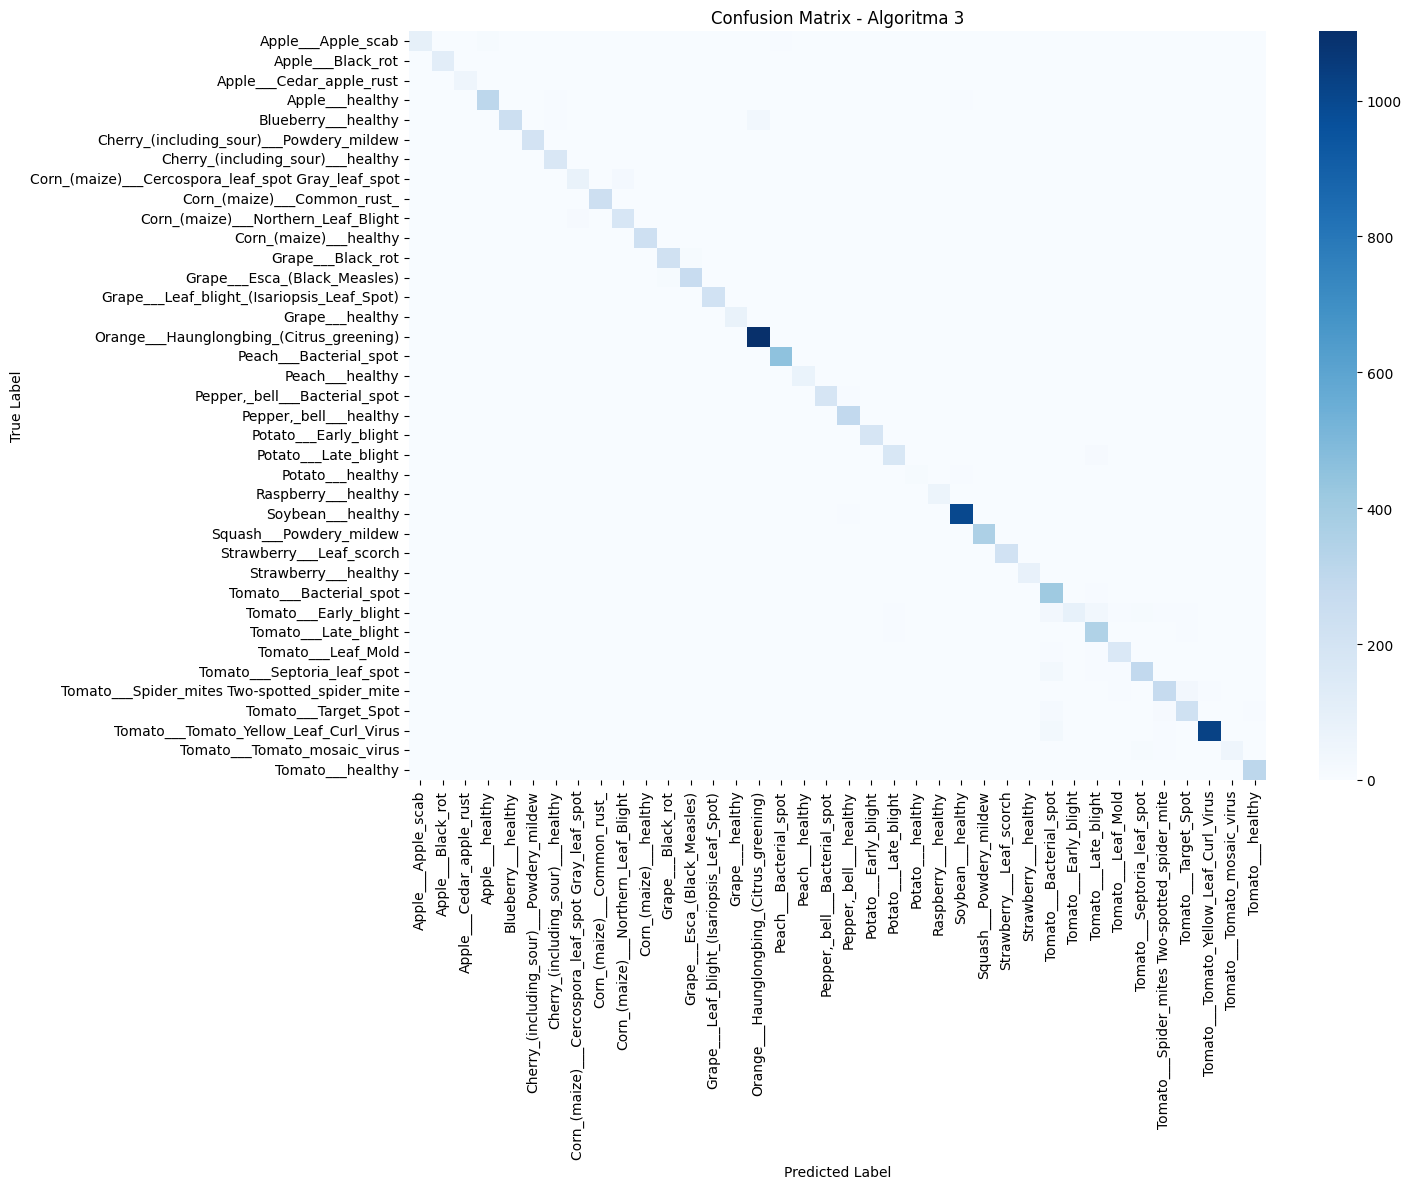

In [9]:
cv_results = np.array(cv_results)
avg_scores = np.mean(cv_results, axis=0)

print(f"=== HASIL RATA-RATA 5-FOLD CROSS VALIDATION (ALGO {PILIHAN_ALGO}) ===")
print(f"Loss             : {avg_scores[0]:.4f}")
print(f"Accuracy         : {avg_scores[1]:.4f}")
print(f"Precision        : {avg_scores[2]:.4f}")
print(f"Recall           : {avg_scores[3]:.4f}")
print(f"ROC-AUC          : {avg_scores[4]:.4f}")
print(f"F1-Score         : {avg_scores[5]:.4f}")
print("===============================================")

print("\nMenghasilkan Confusion Matrix dari Fold 5...")
val_gen_final.reset()
y_true = val_gen_final.classes
y_pred_prob = model.predict(val_gen_final, steps=len(val_gen_final), verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
class_names = list(val_gen_final.class_indices.keys())
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Algoritma {PILIHAN_ALGO}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(f'confusion_matrix_algo{PILIHAN_ALGO}.png', dpi=200)
plt.show()